# **Dependencies import**

In [1]:
from pathlib import Path
from pyspark.ml.feature import StopWordsRemover, Tokenizer
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# **Create sparksession**

In [2]:
spark = (
    SparkSession.builder
        .appName('word_count_w_spark')
            .master('local[*]')
                .getOrCreate()
)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/08/26 10:58:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


# **Transform configs**

In [18]:
COMMON_WORDS_SAMPLE: int = 50
NOISE_WORDS_LENGTH: int = 2
NON_WORDS_PATTERN: str = '[^a-zA-Z\\s]'
PLOT_AXIS_MODE: str = 'off'
PLOT_INTERPOLATION: str = 'bilinear'
PLOT_SIZE_RANGE: tuple = (10, 5)
SOURCE_PATH: str = "../src/data/raw_content/"
WORDCLOUD_WIDTH: int = 800
WORDCLOUD_HEIGHT: int = 400
WORDCLOUD_BACKGROUND_COLOR: str = 'grey'
WORDCLOUD_IMAGE_NAME: str = 'wordcloud.png'

# **text_sample function**

In [4]:
def text_sample(dataframe, column):
    return (
        dataframe.select(column)
            .limit(10)
                .collect()

    )

# **Book options**

In [19]:
[print(file.name) for file in Path(SOURCE_PATH).iterdir() if file.is_file()]

theory_adam_smith.txt
money_market.txt
psychopatology_freud.txt
dreams_freud.txt
hackers.txt
free_software.txt
psichoanalysis_jung.txt
computer_text.txt
iwo_jima.txt
analytical_psicho_jung.txt
great_gatsby.txt
wealth_adam_smith.txt


[None, None, None, None, None, None, None, None, None, None, None, None]

# **Reading source**

In [6]:
text_df = spark.read.text("../src/data/raw_content/dreams_freud.txt")

text_sample(dataframe=text_df, column="value")

[Row(value='The Project Gutenberg eBook of The Interpretation of Dreams, by'),
 Row(value='Sigmund Freud'),
 Row(value=''),
 Row(value='This eBook is for the use of anyone anywhere in the United States and'),
 Row(value='most other parts of the world at no cost and with almost no restrictions'),
 Row(value='whatsoever. You may copy it, give it away or re-use it under the terms'),
 Row(value='of the Project Gutenberg License included with this eBook or online at'),
 Row(value='www.gutenberg.org. If you are not located in the United States, you'),
 Row(value='will have to check the laws of the country where you are located before'),
 Row(value='using this eBook.')]

# **Removing non-words characters**

In [7]:
text_df = (
    text_df
    .select(
        F.regexp_replace(
            F.col('value'),
            NON_WORDS_PATTERN,
            ''
        ).alias('value')
    )
)

text_sample(dataframe=text_df, column="value")

[Row(value='The Project Gutenberg eBook of The Interpretation of Dreams by'),
 Row(value='Sigmund Freud'),
 Row(value=''),
 Row(value='This eBook is for the use of anyone anywhere in the United States and'),
 Row(value='most other parts of the world at no cost and with almost no restrictions'),
 Row(value='whatsoever You may copy it give it away or reuse it under the terms'),
 Row(value='of the Project Gutenberg License included with this eBook or online at'),
 Row(value='wwwgutenbergorg If you are not located in the United States you'),
 Row(value='will have to check the laws of the country where you are located before'),
 Row(value='using this eBook')]

# **Get tokens from text**

In [8]:
tokenizer = Tokenizer(inputCol='value', outputCol='words')
wordsData = tokenizer.transform(text_df)

text_sample(dataframe=wordsData, column="words")

[Row(words=['the', 'project', 'gutenberg', 'ebook', 'of', 'the', 'interpretation', 'of', 'dreams', 'by']),
 Row(words=['sigmund', 'freud']),
 Row(words=['']),
 Row(words=['this', 'ebook', 'is', 'for', 'the', 'use', 'of', 'anyone', 'anywhere', 'in', 'the', 'united', 'states', 'and']),
 Row(words=['most', 'other', 'parts', 'of', 'the', 'world', 'at', 'no', 'cost', 'and', 'with', 'almost', 'no', 'restrictions']),
 Row(words=['whatsoever', 'you', 'may', 'copy', 'it', 'give', 'it', 'away', 'or', 'reuse', 'it', 'under', 'the', 'terms']),
 Row(words=['of', 'the', 'project', 'gutenberg', 'license', 'included', 'with', 'this', 'ebook', 'or', 'online', 'at']),
 Row(words=['wwwgutenbergorg', 'if', 'you', 'are', 'not', 'located', 'in', 'the', 'united', 'states', 'you']),
 Row(words=['will', 'have', 'to', 'check', 'the', 'laws', 'of', 'the', 'country', 'where', 'you', 'are', 'located', 'before']),
 Row(words=['using', 'this', 'ebook'])]

# **Removing stop words**

In [9]:
remover = StopWordsRemover(inputCol='words', outputCol='filtered_words')
filtered_df = remover.transform(wordsData)

text_sample(dataframe=filtered_df, column="filtered_words")

[Row(filtered_words=['project', 'gutenberg', 'ebook', 'interpretation', 'dreams']),
 Row(filtered_words=['sigmund', 'freud']),
 Row(filtered_words=['']),
 Row(filtered_words=['ebook', 'use', 'anyone', 'anywhere', 'united', 'states']),
 Row(filtered_words=['parts', 'world', 'cost', 'almost', 'restrictions']),
 Row(filtered_words=['whatsoever', 'may', 'copy', 'give', 'away', 'reuse', 'terms']),
 Row(filtered_words=['project', 'gutenberg', 'license', 'included', 'ebook', 'online']),
 Row(filtered_words=['wwwgutenbergorg', 'located', 'united', 'states']),
 Row(filtered_words=['check', 'laws', 'country', 'located']),
 Row(filtered_words=['using', 'ebook'])]

# **Counting text words**

In [10]:
word_counts = (
    filtered_df
    .select(
        F.explode(
            'filtered_words'
        ).alias('words')
    )
        .groupBy('words')
            .count()
                .orderBy(
                    'count',
                    ascending=False
                )
)

word_counts.show()

[Stage 4:>                                                          (0 + 1) / 1]

+--------------+-----+
|         words|count|
+--------------+-----+
|              |10710|
|         dream| 3544|
|           one|  916|
|        dreams|  886|
|           may|  587|
|       psychic|  495|
|      thoughts|  428|
|            us|  370|
|          must|  370|
|       content|  370|
|          upon|  347|
|          also|  337|
|       another|  325|
|          wish|  324|
|         first|  324|
|           two|  319|
|          life|  310|
|      footnote|  305|
|          time|  301|
|interpretation|  295|
+--------------+-----+
only showing top 20 rows



# **Remove noise words**

In [11]:
word_counts = (
    word_counts
    .filter(
        F.length('words') > NOISE_WORDS_LENGTH
    )
)

word_counts.show()

+--------------+-----+
|         words|count|
+--------------+-----+
|         dream| 3544|
|           one|  916|
|        dreams|  886|
|           may|  587|
|       psychic|  495|
|      thoughts|  428|
|          must|  370|
|       content|  370|
|          upon|  347|
|          also|  337|
|       another|  325|
|          wish|  324|
|         first|  324|
|           two|  319|
|          life|  310|
|      footnote|  305|
|          time|  301|
|interpretation|  295|
|       thought|  285|
|           day|  279|
+--------------+-----+
only showing top 20 rows



# **Get top 50 common words**

In [12]:
top_words = word_counts.limit(COMMON_WORDS_SAMPLE).collect()

top_words_dict = {row['words'].title(): row['count'] for row in top_words if row['words']}
top_words_dict

{'Dream': 3544,
 'One': 916,
 'Dreams': 886,
 'May': 587,
 'Psychic': 495,
 'Thoughts': 428,
 'Must': 370,
 'Content': 370,
 'Upon': 347,
 'Also': 337,
 'Another': 325,
 'Wish': 324,
 'First': 324,
 'Two': 319,
 'Life': 310,
 'Footnote': 305,
 'Time': 301,
 'Interpretation': 295,
 'Thought': 285,
 'Day': 279,
 'Material': 268,
 'Thus': 262,
 'Part': 250,
 'Fact': 234,
 'Waking': 233,
 'Like': 231,
 'Activity': 225,
 'Sleep': 222,
 'State': 217,
 'Even': 216,
 'Case': 208,
 'Analysis': 207,
 'Made': 205,
 'Place': 204,
 'However': 199,
 'Still': 188,
 'Shall': 188,
 'Found': 186,
 'Work': 180,
 'Often': 179,
 'Little': 178,
 'Without': 177,
 'Unconscious': 174,
 'Way': 174,
 'Years': 169,
 'Means': 169,
 'Person': 168,
 'Man': 167,
 'Father': 167,
 'Memory': 167}

# **Create word cloud of the common words**

In [13]:
word_cloud = (
    WordCloud(
        width=WORDCLOUD_WIDTH,
        height=WORDCLOUD_HEIGHT, 
        background_color=WORDCLOUD_BACKGROUND_COLOR
    ).generate_from_frequencies(top_words_dict)
)

# **Show word_cloud**

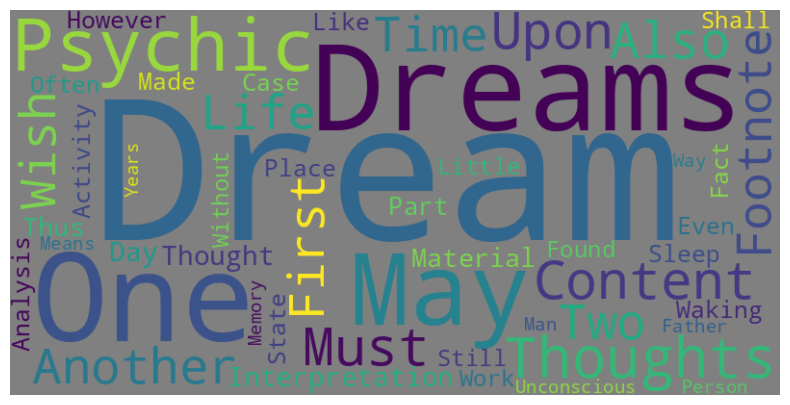

In [14]:
plt.figure(figsize=PLOT_SIZE_RANGE)
plt.imshow(word_cloud, interpolation=PLOT_INTERPOLATION)
plt.axis(PLOT_AXIS_MODE)
plt.show()

# **Saving word_cloud**

In [15]:
# word_cloud.to_file(WORDCLOUD_IMAGE_NAME)